# <center> Modelagem </center>

In [1]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\iurym\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, f1_score,
    precision_score, recall_score,
    roc_curve, confusion_matrix
)

import xgboost as xgb
import warnings
warnings.filterwarnings("ignore")

SEED = 42

In [3]:
# CARREGANDO OS DADOS
X = pd.read_csv("../../data/processed/X_features.csv")
y = pd.read_csv("../../data/processed/y_target.csv").squeeze()

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nDistribuicao do target:")
print(y.value_counts(normalize=True).round(3))

X shape: (149999, 15)
y shape: (149999,)

Distribuicao do target:
SeriousDlqin2yrs
0    0.933
1    0.067
Name: proportion, dtype: float64


In [4]:
# DIVISÃO TREINO-TESTE 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = SEED, stratify=y
)
print(f"\nTreino: {X_train.shape[0]:,} registros")
print(f"Teste: {X_test.shape[0]:,} registros")

# VERIFICANDO A ESTRATIFICAÇÃO
print(f"\nProporcao de inadimplentes no treino: {y_train.mean():.2%}")
print(f"Proporcao de inadimplentes no teste: {y_test.mean():.2%}")


Treino: 119,999 registros
Teste: 30,000 registros

Proporcao de inadimplentes no treino: 6.68%
Proporcao de inadimplentes no teste: 6.68%


In [5]:
# MODELO BASELINE

from sklearn.dummy import DummyClassifier

# PREDIÇÃO DA CLASSE MAJORITÁRIA
baseline = DummyClassifier(strategy="most_frequent", random_state=SEED)
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)
y_proba_baseline = baseline.predict_proba(X_test)[:,1]  

In [6]:
#RESULTADOS

print("--- BASELINE - MAJORITY CLASS ---")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_baseline):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_baseline,zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_baseline,zero_division=0):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_baseline,zero_division=0):.4f}")

--- BASELINE - MAJORITY CLASS ---
ROC-AUC: 0.5000
F1-Score: 0.0000
Recall: 0.0000
Precision: 0.0000


In [7]:
# CRIANDO UMA FUNÇÃO PARA AVALIAR OS MODELOS

def calcular_ks(y_true, y_proba):
    """KS — métrica padrão do mercado de crédito brasileiro"""
    from scipy.stats import ks_2samp
    scores_positivos = y_proba[y_true == 1]
    scores_negativos = y_proba[y_true == 0]
    ks_stat, _ = ks_2samp(scores_positivos, scores_negativos)
    return ks_stat

def avaliar_modelo(nome, modelo, X_train, X_test, y_train, y_test, cv=5):
    """
    Avalia um modelo com métricas completas + validação cruzada estratificada.
    Retorna dicionário com todas as métricas.
    """
    # Predições
    y_proba = modelo.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    # Métricas no teste
    auc = roc_auc_score(y_test, y_proba)
    ks = calcular_ks(y_test, y_proba)
    f1 = f1_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)

    # Validação cruzada estratificada no treino
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=SEED)
    cv_results = cross_validate(
        modelo, X_train, y_train,
        cv=skf,
        scoring="roc_auc",
        return_train_score=True
    )
    cv_auc_mean = cv_results["test_score"].mean()
    cv_auc_std = cv_results["test_score"].std()
    train_auc_mean = cv_results["train_score"].mean()

    print(f"\n{'='*50}")
    print(f"MODELO: {nome}")
    print(f"{'='*50}")
    print(f"ROC-AUC  (teste):       {auc:.4f}")
    print(f"KS       (teste):       {ks:.4f}")
    print(f"F1-Score (teste):       {f1:.4f}")
    print(f"Precision(teste):       {precision:.4f}")
    print(f"Recall   (teste):       {recall:.4f}")
    print(f"ROC-AUC  (CV treino):   {cv_auc_mean:.4f} ± {cv_auc_std:.4f}")
    print(f"ROC-AUC  (CV vs teste): {train_auc_mean:.4f} vs {auc:.4f}")
    print(f"Gap train/test: {abs(train_auc_mean - auc):.4f}", end=" ")
    print("Overfitting?" if abs(train_auc_mean - auc) > 0.05 else "Estável")

    return {
        "modelo": nome,
        "auc_teste": auc,
        "ks_teste": ks,
        "f1_teste": f1,
        "precision_teste": precision,
        "recall_teste": recall,
        "cv_auc_mean": cv_auc_mean,
        "cv_auc_std": cv_auc_std,
        "train_auc_mean": train_auc_mean
    }

In [8]:
# ══════════════════════════════════════════════════════════════
# MODELO 1 — Regressão Logística
# Motivação: modelo linear interpretável, baseline inteligente
# Vantagem: coeficientes explicáveis para o comitê de crédito
# Limitação: assume relação linear entre features e target
# Requer: normalização das features (StandardScaler)
# ══════════════════════════════════════════════════════════════

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",  # trata desbalanceamento
        max_iter=1000,
        random_state=SEED,
        C=0.1                     # regularização L2 — controla multicolinearidade
    ))
])

lr_pipeline.fit(X_train, y_train)
resultado_lr = avaliar_modelo(
    "Regressão Logística", lr_pipeline,
    X_train, X_test, y_train, y_test
)

# ══════════════════════════════════════════════════════════════
# MODELO 2 — Random Forest
# Motivação: ensemble de árvores, captura não-linearidades
# Vantagem: robusto a outliers e multicolinearidade
# Limitação: menos interpretável, mais lento para treinar
# Não requer: normalização
# ══════════════════════════════════════════════════════════════

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,              # limitar profundidade — controla overfitting
    min_samples_leaf=50,      # mínimo de amostras por folha — regularização
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1                 # usar todos os cores disponíveis
)

rf_model.fit(X_train, y_train)
resultado_rf = avaliar_modelo(
    "Random Forest", rf_model,
    X_train, X_test, y_train, y_test
)

# ══════════════════════════════════════════════════════════════
# MODELO 3 — XGBoost
# Motivação: gradient boosting — estado da arte em dados tabulares
# Vantagem: performance superior, lida bem com desbalanceamento
# Limitação: mais hiperparâmetros, risco maior de overfitting
# ══════════════════════════════════════════════════════════════

# scale_pos_weight trata desbalanceamento no XGBoost
# fórmula: n_negativos / n_positivos
scale_pw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pw:.2f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=4,              # árvores rasas — controla overfitting
    learning_rate=0.05,       # passo pequeno — mais robusto
    subsample=0.8,            # amostragem de linhas por árvore
    colsample_bytree=0.8,     # amostragem de features por árvore
    scale_pos_weight=scale_pw,
    random_state=SEED,
    eval_metric="auc",
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
resultado_xgb = avaliar_modelo(
    "XGBoost", xgb_model,
    X_train, X_test, y_train, y_test
)


MODELO: Regressão Logística
ROC-AUC  (teste):       0.8605
KS       (teste):       0.5633
F1-Score (teste):       0.3338
Precision(teste):       0.2139
Recall   (teste):       0.7601
ROC-AUC  (CV treino):   0.8535 ± 0.0069
ROC-AUC  (CV vs teste): 0.8537 vs 0.8605
Gap train/test: 0.0068 Estável



MODELO: Random Forest
ROC-AUC  (teste):       0.8664
KS       (teste):       0.5824
F1-Score (teste):       0.3372
Precision(teste):       0.2147
Recall   (teste):       0.7855
ROC-AUC  (CV treino):   0.8604 ± 0.0069
ROC-AUC  (CV vs teste): 0.8740 vs 0.8664
Gap train/test: 0.0077 Estável
scale_pos_weight: 13.96



MODELO: XGBoost
ROC-AUC  (teste):       0.8701
KS       (teste):       0.5800
F1-Score (teste):       0.3422
Precision(teste):       0.2197
Recall   (teste):       0.7731
ROC-AUC  (CV treino):   0.8628 ± 0.0063
ROC-AUC  (CV vs teste): 0.8846 vs 0.8701
Gap train/test: 0.0145 Estável


In [9]:
# COMPARAÇÃO DOS MODELOS
resultados = [resultado_lr, resultado_rf, resultado_xgb]
df_resultados = pd.DataFrame(resultados).set_index("modelo")

print("--- TABELA COMPARATIVA DE MODELOS ---")
print(df_resultados[[
    "auc_teste", "ks_teste", "f1_teste",
    "precision_teste", "recall_teste",
    "cv_auc_mean", "cv_auc_std", "train_auc_mean"
]].round(4))

df_resultados.to_csv("../../reports/model_comparison.csv")

--- TABELA COMPARATIVA DE MODELOS ---
                     auc_teste  ks_teste  f1_teste  precision_teste  \
modelo                                                                
Regressão Logística     0.8605    0.5633    0.3338           0.2139   
Random Forest           0.8664    0.5824    0.3372           0.2147   
XGBoost                 0.8701    0.5800    0.3422           0.2197   

                     recall_teste  cv_auc_mean  cv_auc_std  train_auc_mean  
modelo                                                                      
Regressão Logística        0.7601       0.8535      0.0069          0.8537  
Random Forest              0.7855       0.8604      0.0069          0.8740  
XGBoost                    0.7731       0.8628      0.0063          0.8846  


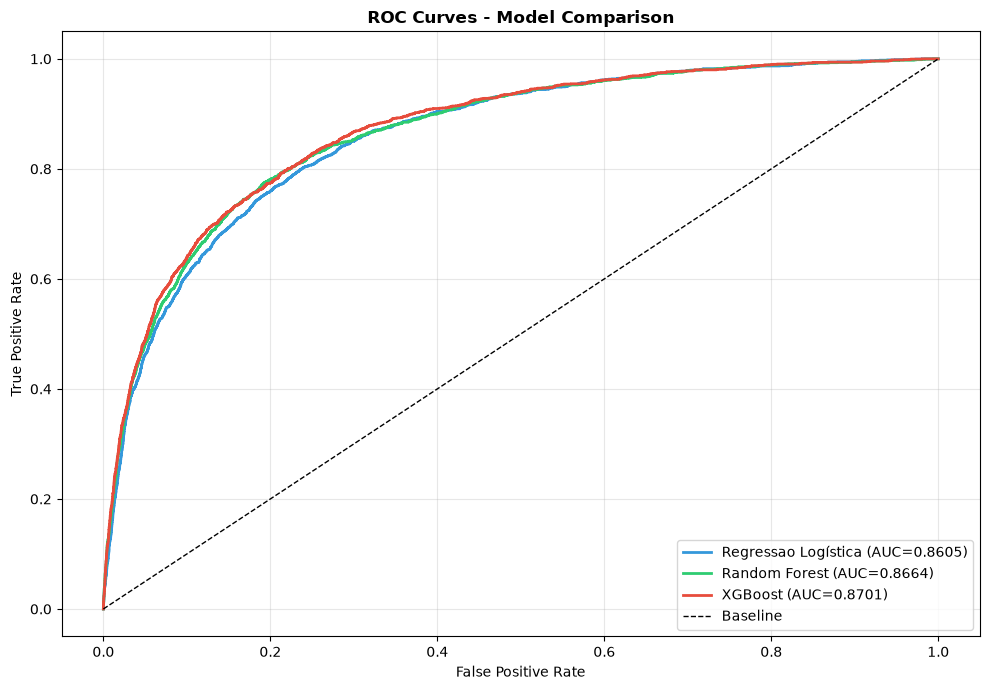

In [10]:
# COMPARAÇÃO DAS CURVAS ROC
fig, ax = plt.subplots(figsize=(10,7))

modelos_plot = [
    ("Regressao Logística", lr_pipeline, "#3498db"),
    ("Random Forest", rf_model, "#2ecc71"),
    ("XGBoost", xgb_model, "#e74c3c")
]

for nome, modelo, cor in modelos_plot:
    y_proba = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f"{nome} (AUC={auc:.4f})", color=cor, linewidth=2)
    
ax.plot([0,1], [0,1], "k--", linewidth=1, label="Baseline")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves - Model Comparison", fontweight="bold")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../../reports/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Regressão logística: significância estatística das variáveis

A regressão logística do `sklearn` não informa p-valores. Para explicar ao negócio **quais variáveis têm relação
estatisticamente significativa com a inadimplência** e **em que direção**, o mesmo modelo é reajustado com o
`statsmodels` (sem regularização), com as features **padronizadas** — assim os coeficientes são comparáveis entre si:

- **coef > 0** → a variável aumenta o risco; **odds ratio** = quanto a chance de inadimplir é multiplicada
  a cada 1 desvio-padrão a mais na variável;
- **p-valor < 0,05** → efeito estatisticamente significativo ao nível de 5%;
- **VIF** (fator de inflação da variância) > 10 indica multicolinearidade forte: o coeficiente e o p-valor daquela
  variável ficam instáveis, porque ela é quase uma combinação das outras.

In [11]:
import warnings
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")  # avisos de matriz singular esperados no diagnóstico abaixo

# 1. DIAGNÓSTICO: as 15 features do modelo são linearmente independentes?
X_std = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=X_train.columns, index=X_train.index)
posto = np.linalg.matrix_rank(X_std.values)
vif_15 = pd.Series([variance_inflation_factor(X_std.values, i) for i in range(X_std.shape[1])], index=X_std.columns)

print(f"Features: {X_std.shape[1]} | posto da matriz: {posto} → {X_std.shape[1] - posto} dependência(s) linear(es) exata(s)")
print()
print("VIF por feature (> 10 = multicolinearidade forte; ~infinito = combinação linear exata):")
print(vif_15.sort_values(ascending=False).map(lambda v: f"{v:,.1f}" if v < 1e6 else "infinito").to_string())

Features: 15 | posto da matriz: 13 → 2 dependência(s) linear(es) exata(s)

VIF por feature (> 10 = multicolinearidade forte; ~infinito = combinação linear exata):
score_risco                             infinito
RevolvingUtilizationOfUnsecuredLines    infinito
NumberOfTimes90DaysLate                 infinito
NumberOfTime60-89DaysPastDueNotWorse    infinito
total_atrasos                           infinito
NumberOfTime30-59DaysPastDueNotWorse    infinito
renda_per_capita                             5.4
MonthlyIncome                                4.7
NumberOfDependents                           3.0
DebtRatio                                    2.9
flag_missing_income                          2.9
teve_atraso_90dias                           2.4
teve_qualquer_atraso                         2.2
NumberOfOpenCreditLinesAndLoans              1.3
age                                          1.2


Duas features criadas são **combinações lineares exatas** de outras:

- `total_atrasos` = atrasos de 30-59 + 60-89 + 90 dias;
- `score_risco` = 0,5 · rotativo + 0,3 · atrasos de 90 dias + 0,2 · `total_atrasos` (todos normalizados).

Para o XGBoost isso não é problema (árvores escolhem um corte por vez e o desempenho foi validado). Mas numa
regressão logística os coeficientes **deixam de ser únicos** — infinitas combinações dão o mesmo ajuste —, então
p-valores e sinais não podem ser interpretados. Para a leitura de negócio, a logística é reajustada **sem as duas
features derivadas**, mantendo seus componentes.

In [12]:
# 2. REGRESSÃO LOGÍSTICA PARA INFERÊNCIA — sem as combinações lineares exatas
derivadas = ["total_atrasos", "score_risco"]
X_inf = X_std.drop(columns=derivadas)
logit = sm.Logit(y_train, sm.add_constant(X_inf)).fit(disp=False, maxiter=200)

ic = logit.conf_int()
tabela_logit = pd.DataFrame({
    "coef": logit.params,
    "odds_ratio": np.exp(logit.params),
    "ic95_inf": np.exp(ic[0]),
    "ic95_sup": np.exp(ic[1]),
    "p_valor": logit.pvalues,
}).drop(index="const")
tabela_logit["significativa_5%"] = np.where(tabela_logit["p_valor"] < 0.05, "sim", "não")
tabela_logit["direcao"] = np.where(tabela_logit["coef"] > 0, "aumenta o risco", "reduz o risco")
tabela_logit["vif"] = [variance_inflation_factor(X_inf.values, i) for i in range(X_inf.shape[1])]

print(f"Features: {X_inf.shape[1]} | posto: {np.linalg.matrix_rank(X_inf.values)} | "
      f"pseudo R² (McFadden): {logit.prsquared:.4f} | n = {int(logit.nobs):,}")
print(tabela_logit.sort_values("p_valor").round(4).to_string())

Features: 13 | posto: 13 | pseudo R² (McFadden): 0.2479 | n = 119,999
                                        coef  odds_ratio  ic95_inf  ic95_sup  p_valor significativa_5%          direcao       vif
RevolvingUtilizationOfUnsecuredLines  0.6737      1.9615    1.9094    2.0151   0.0000              sim  aumenta o risco    1.2581
teve_qualquer_atraso                  0.5185      1.6795    1.6343    1.7260   0.0000              sim  aumenta o risco    2.2210
teve_atraso_90dias                    0.2990      1.3485    1.3210    1.3767   0.0000              sim  aumenta o risco    2.3817
age                                  -0.2204      0.8022    0.7781    0.8271   0.0000              sim    reduz o risco    1.1755
NumberOfOpenCreditLinesAndLoans       0.1791      1.1962    1.1618    1.2315   0.0000              sim  aumenta o risco    1.3023
DebtRatio                             0.1995      1.2207    1.1711    1.2725   0.0000              sim  aumenta o risco    2.9190
flag_missing_income 

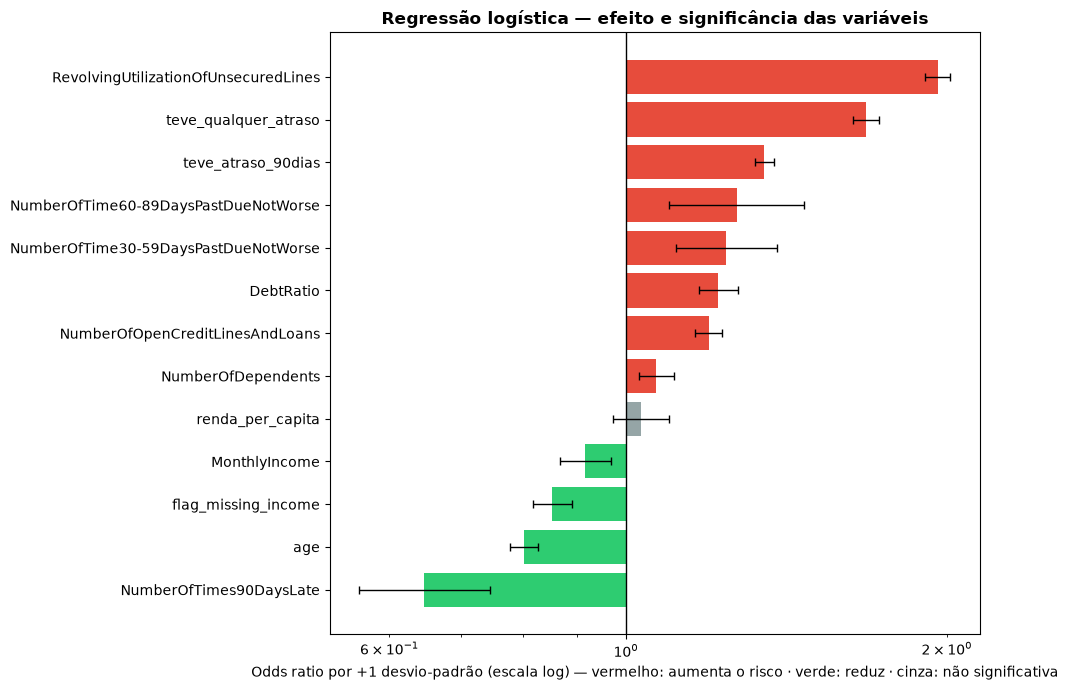

In [13]:
# Gráfico: odds ratio por variável (com IC 95%), destacando as significativas
t = tabela_logit.sort_values("odds_ratio")
cores = ["#e74c3c" if (s == "sim" and o > 1) else "#2ecc71" if s == "sim" else "#95a5a6"
         for s, o in zip(t["significativa_5%"], t["odds_ratio"])]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(t.index, t["odds_ratio"] - 1, left=1, color=cores)
ax.errorbar(t["odds_ratio"], t.index, xerr=[t["odds_ratio"] - t["ic95_inf"], t["ic95_sup"] - t["odds_ratio"]],
            fmt="none", ecolor="black", capsize=3, linewidth=1)
ax.axvline(1, color="black", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Odds ratio por +1 desvio-padrão (escala log) — vermelho: aumenta o risco · verde: reduz · cinza: não significativa")
ax.set_title("Regressão logística — efeito e significância das variáveis", fontweight="bold")
plt.tight_layout()
plt.savefig("../../reports/logit_odds_ratio.png", dpi=150, bbox_inches="tight")
plt.show()

### Leitura para o negócio

**Efeitos significativos (p < 0,05) e com direção coerente com o risco de crédito** — odds ratio por +1 desvio-padrão:

| Variável | Odds ratio | Leitura |
|---|---|---|
| `RevolvingUtilizationOfUnsecuredLines` | **1,96** | maior efeito do modelo: usar mais o limite rotativo quase dobra a chance de inadimplir |
| `teve_qualquer_atraso` | 1,68 | já ter atrasado (qualquer janela) aumenta o risco |
| `teve_atraso_90dias` | 1,35 | um atraso grave pesa além do atraso em geral |
| `DebtRatio` | 1,22 | maior comprometimento de renda, maior risco |
| `NumberOfOpenCreditLinesAndLoans` | 1,20 | mais linhas de crédito abertas, maior exposição |
| `NumberOfDependents` | 1,07 | mais dependentes, maior custo de vida |
| `MonthlyIncome` | 0,92 | mais renda, menor risco |
| `age` | **0,80** | o risco cai com a idade — maior efeito protetor |
| `flag_missing_income` | 0,85 | quem não informou renda inadimple menos (coerente com o EDA: 5,6% vs 7,0%) |

**Três achados de diagnóstico:**

1. **Combinações lineares exatas.** `total_atrasos` e `score_risco` são somas ponderadas de outras features: a matriz
   tem posto 13, não 15. Não afeta o XGBoost, mas impede interpretar uma logística com as 15 — por isso a inferência
   foi feita sem as duas.
2. **`renda_per_capita` não é significativa (p = 0,30)** quando renda e dependentes já estão no modelo — ela é a razão
   entre as duas. Num modelo linear parcimonioso, seria removida; no XGBoost foi mantida pelo IV (0,096).
3. **`NumberOfTimes90DaysLate` com sinal invertido (odds ratio 0,65) e VIF ~120 nas três contagens de atraso.** A causa
   são os **códigos especiais 96/98**: aparecem nas **mesmas 269 linhas nas três colunas** (54,6% de inadimplência) e,
   sozinhos, elevam a correlação entre as contagens de ~0,2–0,3 para **0,98–0,99**. O coeficiente individual deixa de
   ser interpretável — o efeito do atraso grave é lido em `teve_atraso_90dias`. Foi este diagnóstico que levou o
   pipeline de produção (`CreditPreprocessor`) a tratar 96/98 explicitamente.

Pseudo R² de McFadden de 0,25 — um ajuste bom para modelos de risco de crédito (valores de 0,2 a 0,4 são considerados
muito bons para essa métrica).

In [14]:
# CONCLUSÃO
# O XGBoost foi escolhido pela combinação de maior AUC e menor variância na validação cruzada.
# A diferença de KS em relação ao Random Forest é de 0.002 — marginal.
# Para um ambiente que exige explicabilidade regulatória, aplicaremos SHAP values na fase de avaliação.

In [15]:
import mlflow
import mlflow.sklearn
import mlflow.xgboost
import pickle
import json

In [16]:
from mlflow.models.signature import infer_signature
signature = infer_signature(X_train, xgb_model.predict_proba(X_train)[:,1])

mlflow.set_experiment("credit-scoring")

with mlflow.start_run(run_name="XGBoost_final_v2"):
    
    # registrando parâmetros
    mlflow.log_params({
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "scale_pos_weight": round(scale_pw, 2),
        "seed" : SEED
    })
    
    # registrando métricas
    mlflow.log_metrics({
        "auc_teste": resultado_xgb["auc_teste"],
        "ks_teste": resultado_xgb["ks_teste"],
        "f1_teste": resultado_xgb["f1_teste"],
        "precision_teste": resultado_xgb["precision_teste"],
        "recall_teste": resultado_xgb["recall_teste"],
        "cv_auc_mean": resultado_xgb["cv_auc_mean"],
        "cv_auc_std": resultado_xgb["cv_auc_std"]
    })
    
    # registrando o modelo
    mlflow.xgboost.log_model(xgb_model, name = "model", signature=signature, input_example=X_train.iloc[:5])
    print("Modelo registrado no MLflow com sucesso!")
    
# SALVANDO O MODELO LOCALMENTE
with open("../../models/xgboost_credit.pkl", "wb") as f:
    pickle.dump(xgb_model, f)
    
# SALVANDO A LISTA DE FEATURES
features_modelo_lista = X_train.columns.tolist()
with open("../../models/features.json", "w") as f:
    json.dump(features_modelo_lista, f, indent=2)
    
print(f"\nModelo salvo em modelos/xgboost_credit.pkl")
print(f"Lista de features salva em modelos/features.json")
print(f"\nFeatures do Modelo ({len(features_modelo_lista)}):")
for f in features_modelo_lista:
    print(f"- {f}")

Modelo registrado no MLflow com sucesso!

Modelo salvo em modelos/xgboost_credit.pkl
Lista de features salva em modelos/features.json

Features do Modelo (15):
- RevolvingUtilizationOfUnsecuredLines
- NumberOfTimes90DaysLate
- NumberOfTime30-59DaysPastDueNotWorse
- NumberOfTime60-89DaysPastDueNotWorse
- age
- MonthlyIncome
- NumberOfOpenCreditLinesAndLoans
- DebtRatio
- NumberOfDependents
- flag_missing_income
- renda_per_capita
- teve_atraso_90dias
- teve_qualquer_atraso
- total_atrasos
- score_risco
